<a href="https://colab.research.google.com/github/AsmaaaSalis/agriprice-teller-intelligence/blob/main/03_exploratory_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 3: Exploratory Data Analysis

Exploring the clean monthly price dataset from Notebook 2: price trends, the 2023 price
shock, seasonal patterns, and how Borno and Yobe compare.
Scope: retail prices per kg (NGN), January 2016 to October 2026, Borno and Yobe,
millet, rice (local) and groundnuts.

Input: clean_monthly_prices.csv (from Notebook 2).

In [1]:
# Importing libraries

import pandas as pd              # Data tables
import numpy as np               # Missing values and maths
import matplotlib.pyplot as plt  # Charts

# Setting display options
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 100)

print('Libraries loaded')

Libraries loaded


### 1. Loading and checking the clean data

In [2]:
# Loading the clean monthly dataset (output of Notebook 2)
df = pd.read_csv('clean_monthly_prices.csv', parse_dates=['date'])

# Checking the size of the table (rows, columns)
print(df.shape)

# Viewing the first 5 rows
df.head()

(780, 6)


,date,state,commodity,price_per_kg_ngn,n_markets,is_interpolated
0,2016-01-01,Borno,Groundnuts,NaN,1,False
1,2016-02-01,Borno,Groundnuts,NaN,0,False
2,2016-03-01,Borno,Groundnuts,NaN,0,False
3,2016-04-01,Borno,Groundnuts,NaN,0,False
4,2016-05-01,Borno,Groundnuts,NaN,0,False


In [3]:
# Checking the data type of each column
print(df.dtypes)

# Counting missing values in each column
print(df.isnull().sum())

date                datetime64[ns]
state                       object
commodity                   object
price_per_kg_ngn           float64
n_markets                    int64
is_interpolated               bool
dtype: object
date                 0
state                0
commodity            0
price_per_kg_ngn    96
n_markets            0
is_interpolated      0
dtype: int64


### 2. Price trends
Looking at the series first: direction, the 2023 shock, and where the gaps are.

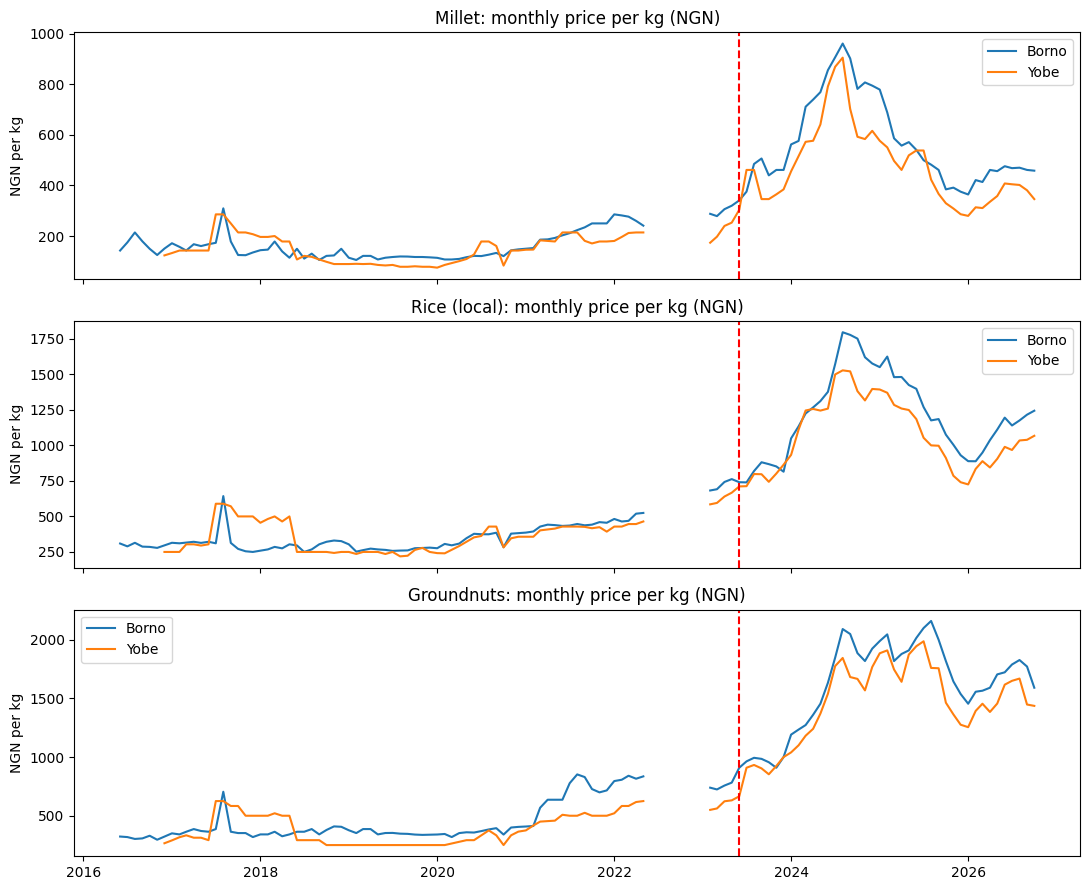

In [4]:
# Plotting monthly price per kg, one chart per crop
crops = ['Millet', 'Rice (local)', 'Groundnuts']
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

for ax, crop in zip(axes, crops):
    for state in ['Borno', 'Yobe']:
        d = df[(df['commodity'] == crop) & (df['state'] == state)]
        ax.plot(d['date'], d['price_per_kg_ngn'], label=state)
    # Marking mid-2023 (fuel subsidy removal and naira unification)
    ax.axvline(pd.Timestamp('2023-06-01'), color='red', linestyle='--')
    ax.set_title(crop + ': monthly price per kg (NGN)')
    ax.set_ylabel('NGN per kg')
    ax.legend()

plt.tight_layout()
plt.show()

In [5]:
# Calculating the median price per kg for each year and crop (Borno and Yobe together)
yearly = df.groupby([df['date'].dt.year, 'commodity'])['price_per_kg_ngn'].median().unstack().round(0)
print(yearly)

commodity  Groundnuts  Millet  Rice (local)
date                                       
2016            312.0   150.0         288.0
2017            364.0   164.0         314.0
2018            352.0   127.0         280.0
2019            293.0    98.0         259.0
2020            340.0   121.0         346.0
2021            504.0   186.0         429.0
2022            710.0   228.0         464.0
2023            906.0   346.0         743.0
2024           1601.0   726.0        1347.0
2025           1876.0   499.0        1217.0
2026           1578.0   406.0        1012.0


### 3. Year-on-year growth
2026 covers January to October only.

In [6]:
# Calculating year-on-year growth in median price per kg (%)
growth = (yearly.pct_change() * 100).round(0)
print(growth)

commodity  Groundnuts  Millet  Rice (local)
date                                       
2016              NaN     NaN           NaN
2017             17.0     9.0           9.0
2018             -3.0   -23.0         -11.0
2019            -17.0   -23.0          -7.0
2020             16.0    23.0          34.0
2021             48.0    54.0          24.0
2022             41.0    23.0           8.0
2023             28.0    52.0          60.0
2024             77.0   110.0          81.0
2025             17.0   -31.0         -10.0
2026            -16.0   -19.0         -17.0


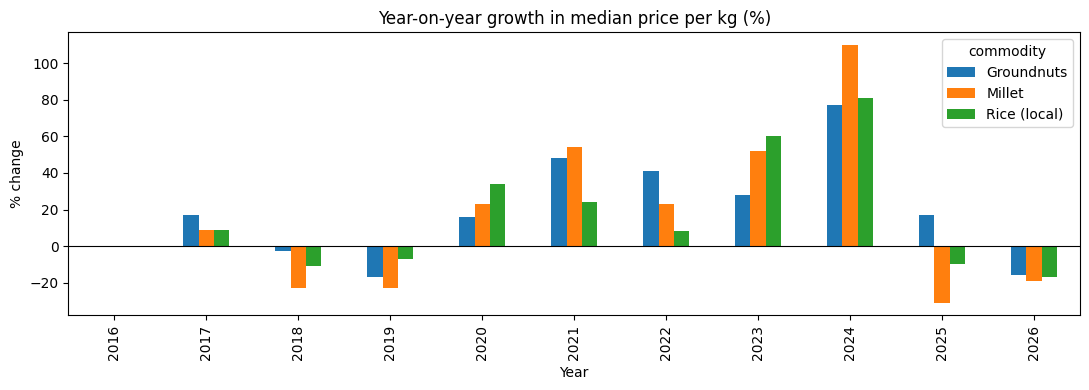

In [7]:
# Plotting year-on-year growth in median price per kg
growth.plot(kind='bar', figsize=(11, 4))
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Year-on-year growth in median price per kg (%)')
plt.xlabel('Year')
plt.ylabel('% change')
plt.tight_layout()
plt.show()

### 4. Seasonality
Comparing each price with its 12-month average removes the long-term rise, so the yearly pattern shows.

In [8]:
# Sorting so each series runs in date order
df = df.sort_values(['state', 'commodity', 'date'])

# Calculating the 12-month moving average (the local trend) for each state and crop
df['trend'] = (df.groupby(['state', 'commodity'])['price_per_kg_ngn']
                 .transform(lambda s: s.rolling(12, center=True, min_periods=9).mean()))

# Comparing each price with its trend (1.00 = on trend)
df['relative'] = df['price_per_kg_ngn'] / df['trend']

# Checking a few rows
print(df[['date', 'state', 'commodity', 'price_per_kg_ngn', 'trend', 'relative']].dropna().head())
print('Months with a relative value:', df['relative'].notna().sum(), 'of', len(df))

         date  state   commodity  price_per_kg_ngn       trend  relative
8  2016-09-01  Borno  Groundnuts        306.818182  320.959596  0.955940
9  2016-10-01  Borno  Groundnuts        329.545455  325.227273  1.013277
10 2016-11-01  Borno  Groundnuts        295.454545  330.785124  0.893192
11 2016-12-01  Borno  Groundnuts        322.727273  334.053030  0.966096
12 2017-01-01  Borno  Groundnuts        350.000000  337.462121  1.037153
Months with a relative value: 624 of 780


In [9]:
# Adding the calendar month (1 = January, 12 = December)
df['month_num'] = df['date'].dt.month

# Averaging the relative value by calendar month and crop
seasonal = df.groupby(['month_num', 'commodity'])['relative'].mean().unstack()

# Converting to % above (+) or below (-) trend
seasonal_pct = ((seasonal - 1) * 100).round(1)
print(seasonal_pct)

commodity  Groundnuts  Millet  Rice (local)
month_num                                  
1                -3.7    -5.6          -4.2
2                -2.2    -4.5          -2.9
3                -0.4    -0.1          -0.1
4                -1.5    -1.7           0.1
5                -1.3    -3.0           1.8
6                -0.9     2.6          -0.5
7                 8.9    11.8           2.1
8                14.8    16.9           9.8
9                 4.0     3.0           3.4
10               -3.8    -9.5          -3.9
11               -5.7    -7.6          -3.4
12               -5.1    -5.9          -4.9


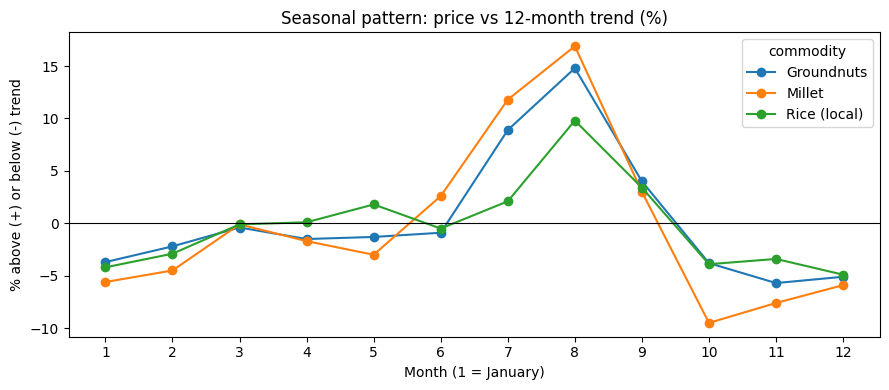

In [10]:
# Plotting average price relative to trend, by calendar month
seasonal_pct.plot(kind='line', marker='o', figsize=(9, 4))
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(range(1, 13))
plt.title('Seasonal pattern: price vs 12-month trend (%)')
plt.xlabel('Month (1 = January)')
plt.ylabel('% above (+) or below (-) trend')
plt.tight_layout()
plt.show()

### 5. Borno vs Yobe

In [11]:
# Putting Borno and Yobe prices side by side
wide = df.pivot_table(index=['date', 'commodity'], columns='state',
                      values='price_per_kg_ngn').reset_index()

# Calculating correlations for each crop
rows = []
for crop, g in wide.groupby('commodity'):
    g = g.sort_values('date')
    rows.append({'commodity': crop,
                 'months_both': int(g[['Borno', 'Yobe']].dropna().shape[0]),
                 'level_corr': round(g['Borno'].corr(g['Yobe']), 2),
                 'change_corr': round(g['Borno'].pct_change(fill_method=None)
                                      .corr(g['Yobe'].pct_change(fill_method=None)), 2)})
print(pd.DataFrame(rows))

      commodity  months_both  level_corr  change_corr
0    Groundnuts          111        0.98         0.19
1        Millet          111        0.97         0.18
2  Rice (local)          111        0.98         0.22


In [12]:
# Calculating Yobe price as a ratio of Borno price, in months when both have a price
both = wide.dropna(subset=['Borno', 'Yobe']).copy()
both['yobe_vs_borno'] = both['Yobe'] / both['Borno']
print(both.groupby('commodity')['yobe_vs_borno'].agg(['median', 'min', 'max']).round(2))

              median   min   max
commodity                       
Groundnuts      0.83  0.59  1.66
Millet          0.83  0.60  1.72
Rice (local)    0.91  0.74  2.00


## EDA findings

- Prices were broadly flat from 2016 to 2020 (median roughly 100-350 NGN/kg depending on crop), rose from 2021, and jumped in 2024: year-on-year growth of +77% (groundnuts), +110% (millet) and +81% (rice). The jump follows the mid-2023 fuel subsidy removal and exchange rate unification (consistent with, not proof of, a policy effect).
- 2023 already shows large rises (+28% to +60%), and 2021 also rose sharply (+24% to +54%), so 2023 is not the only major shift.
- After the peak, prices fell: 2025 was down for millet (-31%) and rice (-10%) while groundnuts rose (+17%); January to October 2026 is lower again for all three (-16% to -19% vs 2025).
- Seasonality: prices are highest in August (+15% groundnuts, +17% millet, +10% rice above trend) and July, and lowest from October to December (millet -9.5% in October). This is consistent with a lean season before harvest.
- Borno and Yobe share the same long-term rise (level correlation 0.97-0.98), but their monthly changes are only weakly correlated (0.18-0.22). Yobe prices are typically about 83% of Borno's for groundnuts and millet and 91% for rice, with large month-to-month variation (59% to 200%).
- Implications for forecasting: models must cope with a structural break in 2023; a seasonal component is justified; each state should be modelled separately.